# Modelos del lenguaje con RNNs

En esta parte, vamos a entrenar un modelo del lenguaje basado en caracteres con Recurrent Neural Networks. Asimismo, utilizaremos el modelo para generar texto. En particular, alimentaremos nuestro modelo con obras de la literatura clásica en castellano para obtener una red neuronal que sea capaz de "escribir" fragmentos literarios.

<center><img src="https://upload.wikimedia.org/wikipedia/commons/d/d8/El_ingenioso_hidalgo_don_Quijote_de_la_Mancha.jpg" style="text-align: center" height="300px"></center>

El dataset a utilizar consistirá en un archivo de texto con el contenido íntegro en castellano antiguo de El Ingenioso Hidalgo Don Quijote de la Mancha, disponible de manera libre en la página de [Project Gutenberg](https://www.gutenberg.org).

## Resumen de la solución y decisiones tomadas

| Decisión | Valor | Justificación |
|---|---|---|
| Unidad de modelado | **carácter** | Evita tokenizar y permite aprender puntuación, mayúsculas (aquí eliminadas) y erratas del texto original. |
| `SEQ_LENGTH` | **30** | Valor propuesto en el enunciado: suficiente contexto (~5-6 palabras) sin disparar el coste de la LSTM. |
| `MAX_SEQUENCES` | **250 000** | Con one-hot de 61 caracteres, 250k secuencias ocupan ~1.8 GB en `float32`. Es el mayor tamaño que entrena con holgura en CPU/RAM sin agotar memoria (el valor de 500k pediría ~3.7 GB solo para `X`). |
| Representación de entrada | **one-hot** | Es la indicada en el enunciado; para 61 símbolos es eficiente y no necesita capa `Embedding`. |
| Arquitectura | **LSTM(128) -> Dense(61, softmax)** | Suficiente capacidad para modelar dependencias de ~30 caracteres; `softmax` da una distribución válida para muestrear. |
| Optimizador / loss | **Adam + categorical_crossentropy** | Adam converge rápido con pocos epochs; la loss categórica es la verosimilitud negativa del siguiente carácter. |
| Epochs | **12** | Con ~2 000 pasos/epoch la loss se estabiliza y el texto generado ya es reconocible como castellano. |
| Validación | 10 000 secuencias reservadas | Permite comprobar que no hay sobreajuste sin sacrificar datos de entrenamiento. |

> **Nota de reproducibilidad:** el notebook busca el `.txt` del Quijote en la carpeta actual y en `/content` (sin importar si el nombre lleva espacios o guiones bajos); si no lo encuentra, Colab pide subirlo. Basta con subir el archivo a `/content`.

> **Modo de ejecución.** El notebook detecta si hay GPU. Con GPU usa la configuración de la tabla (250 000 secuencias, 12 epochs, texto de 300 caracteres). Sin GPU reduce el cómputo para terminar a tiempo: 150 000 secuencias, 5 epochs, 150 caracteres por muestra y experimentos de 2 epochs sobre 50 000 secuencias.

## 1. Carga y procesado del texto

Primero, vamos a cargar el libro e inspeccionar los datos. El fichero es una versión en `.txt` del libro de Don Quijote, a la cual se le han borrado introducciones, licencias y otras secciones para dejarlo con el contenido real de la novela.

In [1]:
import os
import glob
import random
import io

import numpy as np
import keras
import tensorflow as tf
import matplotlib.pyplot as plt
from keras.callbacks import LambdaCallback
from keras.models import Sequential
from keras.layers import Input, Dense, LSTM, GRU

def find_quijote():
    """Busca cualquier .txt del Quijote (con o sin espacios en el nombre) en la carpeta actual y /content."""
    cands = []
    for root in [".", "/content", "/content/drive/MyDrive", os.path.expanduser("~/Downloads")]:
        if os.path.isdir(root):
            cands += glob.glob(os.path.join(root, "**", "*.txt"), recursive=True)
    cands = [c for c in cands if "quijote" in os.path.basename(c).lower()]
    # El archivo correcto pesa ~2 MB; se descartan archivos pequeños o vacíos
    cands = [c for c in cands if os.path.getsize(c) > 1_000_000]
    return max(cands, key=os.path.getsize) if cands else None

path = find_quijote()
if path is None:
    try:
        from google.colab import files
        print("No se encontró el texto del Quijote. Sube el archivo .txt (~2 MB):")
        files.upload()
        path = find_quijote()
    except ImportError:
        pass

if path is None:
    raise FileNotFoundError("Sube 'Don Quijote de la Mancha.txt' (~2 MB) a /content y vuelve a ejecutar esta celda.")

print("Corpus:", path)
print("Tamaño en disco: {:.2f} MB".format(os.path.getsize(path) / 1e6))

GPU = len(tf.config.list_physical_devices("GPU")) > 0
print("Modo:", "GPU (configuración completa)" if GPU else "CPU (configuración reducida)")

No se encontró el texto del Quijote. Sube el archivo .txt (~2 MB):


Saving Don Quijote de la Mancha.txt to Don Quijote de la Mancha.txt
Corpus: ./Don Quijote de la Mancha.txt
Tamaño en disco: 2.15 MB
Modo: CPU (configuración reducida)


Una vez localizado, leemos el contenido en una variable y lo pasamos a minúsculas para que el modelo no tenga que aprender por separado `A` y `a` (reduce el vocabulario y, con él, los parámetros de salida).

Dos detalles del preprocesado:

* Leemos con `encoding="utf-8"` para conservar tildes, eñes y los signos `¿ ¡ « »`.
* Normalizamos los saltos de línea `CRLF -> LF`; de lo contrario, `\r` se convertiría en un carácter más del vocabulario que no aporta información.

**1.1.** Leer todo el contenido del fichero en una única variable ***text*** y convertir el string a minúsculas.

In [2]:
with io.open(path, "r", encoding="utf-8") as f:
    text = f.read()

text = text.replace("\r\n", "\n").replace("\r", "\n")

text = text.lower()

# Comprobación: si no es el Quijote (p. ej. una página HTML descargada por error), se detiene aquí
assert "en un lugar de la mancha" in text and len(text) > 1_000_000, "El archivo cargado no es el texto del Quijote"

print("Longitud del texto: {:,} caracteres".format(len(text)))

Longitud del texto: 2,071,198 caracteres


Comprobamos que la variable contiene el resultado deseado, con el comienzo tan característico del Quijote.

In [3]:
print("Longitud del texto: {}".format(len(text)))
print(text[0:300])

Longitud del texto: 2071198
capítulo primero. que trata de la condición y ejercicio del famoso hidalgo
don quijote de la mancha


en un lugar de la mancha, de cuyo nombre no quiero acordarme, no ha mucho
tiempo que vivía un hidalgo de los de lanza en astillero, adarga antigua,
rocín flaco y galgo corredor. una olla de algo más


## 2. Procesado de los datos

Una de las grandes ventajas de trabajar con modelos que utilizan caracteres en vez de palabras es que no necesitamos tokenizar el texto. Nuestro modelo funcionará directamente con los caracteres del texto, incluyendo espacios, saltos de línea, etc.

Un modelo del lenguaje con RNNs acepta una serie de caracteres y predice el siguiente carácter de la secuencia:

* "*el ingenioso don qui*" -> predicción: **j**
* "*el ingenioso don quij*" -> predicción: **o**

Usaremos la variante **secuencia a carácter** (la segunda del enunciado): dada una ventana de `SEQ_LENGTH` caracteres, predecir un único carácter. Es más simple de implementar y de entrenar que la variante secuencia-a-secuencia, y para generar texto solo hay que ir deslizando la ventana.

#### 2.1. Obtención de los caracteres y mapas de caracteres

Necesitamos saber qué caracteres aparecen en el texto para asignarles un índice de 0 a *num_chars* - 1:

1. Número de caracteres únicos.
2. Diccionario `char -> índice`.
3. Diccionario inverso `índice -> char`.

Usamos `sorted(set(text))` para que el vocabulario sea determinista y reproducible entre ejecuciones.

In [4]:
chars = sorted(set(text))
num_chars = len(chars)

char_to_indices = {ch: i for i, ch in enumerate(chars)}
indices_to_char = {i: ch for i, ch in enumerate(chars)}

print("Número de caracteres únicos (vocabulario):", num_chars)
print("Caracteres:", "".join(chars))
print("Ejemplo de mapa char->índice:", {c: char_to_indices[c] for c in "abc "})

Número de caracteres únicos (vocabulario): 61
Caracteres: 
 !"'(),-.01234567:;?]abcdefghijlmnopqrstuvwxyz¡«»¿àáéíïñóùúü
Ejemplo de mapa char->índice: {'a': 22, 'b': 23, 'c': 24, ' ': 1}


#### 2.2. Obtención de secuencias de entrada y carácter a predecir

Recorremos el texto con una ventana deslizante de `SEQ_LENGTH` caracteres. En cada posición guardamos la ventana en ***sequences*** y el carácter inmediatamente posterior en ***next_chars***.

Ejemplo con "Don Quijote" y `SEQ_LENGTH = 5`:

* *sequences* = `["Don Q", "on Qu", "n Qui", " Quij", "Quijo", "uijot"]`
* *next_chars* = `['u', 'i', 'j', 'o', 't', 'e']`

In [5]:
SEQ_LENGTH = 30

sequences = []
next_chars = []

for i in range(0, len(text) - SEQ_LENGTH):
    sequences.append(text[i:i + SEQ_LENGTH])
    next_chars.append(text[i + SEQ_LENGTH])

print("Secuencias generadas:", len(sequences))

Secuencias generadas: 2071168


Indicamos el tamaño del *training set* generado y comprobamos con un ejemplo que la ventana y su etiqueta están alineadas.

In [6]:
print("Número de secuencias (pares entrada -> siguiente carácter): {:,}".format(len(sequences)))
print("Número de caracteres a predecir: {:,}".format(len(next_chars)))
print()
print("Ejemplo de la posición 1000:")
print("  input :", repr(sequences[1000]))
print("  output:", repr(next_chars[1000]))

Número de secuencias (pares entrada -> siguiente carácter): 2,071,168
Número de caracteres a predecir: 2,071,168

Ejemplo de la posición 1000:
  input : 'cir que tenía el sobrenombre d'
  output: 'e'


Como el Quijote es muy largo y tenemos muchas secuencias, podríamos tener problemas de memoria. Por ello, elegimos un número máximo de ellas.

**Decisión:** se barajan las secuencias y se conservan **250 000**. Con 61 caracteres y `float32`, `X` ocupa `250000 x 30 x 61 x 4 B ~ 1.8 GB`, un tamaño seguro en una máquina de 16 GB y suficiente para que el modelo aprenda el estilo. Barajar evita quedarnos solo con el primer tercio del libro (que sesgaría el vocabulario y los temas).

**Validación:** reservamos las últimas 10 000 secuencias (tras el barajado) para medir la loss en datos no vistos.

In [7]:
MAX_SEQUENCES = 250000 if GPU else 150000
NUM_VAL = 10000

perm = np.random.permutation(len(sequences))
sequences, next_chars = np.array(sequences), np.array(next_chars)
sequences, next_chars = sequences[perm], next_chars[perm]
sequences, next_chars = list(sequences[:MAX_SEQUENCES]), list(next_chars[:MAX_SEQUENCES])

print("Secuencias conservadas:", len(sequences))

Secuencias conservadas: 150000


#### 2.3. Obtención de input `X` y output `y` para el modelo

Usamos *one-hot encoding*: cada carácter es un vector de `num_chars` posiciones con un 1 en su índice. Así, **X** tendrá shape *(num_sequences, seq_length, num_chars)* e **y** tendrá shape *(num_sequences, num_chars)*.

Trabajamos en `float32` (no `float64`) para no duplicar el uso de memoria: 1.8 GB frente a 3.7 GB.

In [8]:
NUM_CHARS = num_chars
NUM_SEQUENCES = len(sequences)

X = np.zeros((NUM_SEQUENCES, SEQ_LENGTH, NUM_CHARS), dtype=np.float32)
y = np.zeros((NUM_SEQUENCES, NUM_CHARS), dtype=np.float32)

for i, seq in enumerate(sequences):
    for t, ch in enumerate(seq):
        X[i, t, char_to_indices[ch]] = 1.0
    y[i, char_to_indices[next_chars[i]]] = 1.0

X_train, y_train = X[:-NUM_VAL], y[:-NUM_VAL]
X_val, y_val = X[-NUM_VAL:], y[-NUM_VAL:]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)
print("Memoria de X: {:.2f} GB".format(X.nbytes / 1e9))
print("Suma de one-hot en la posición 0 (debe ser 1):", X[0, 0].sum())

X_train: (140000, 30, 61) | y_train: (140000, 61)
X_val:   (10000, 30, 61) | y_val:   (10000, 61)
Memoria de X: 1.10 GB
Suma de one-hot en la posición 0 (debe ser 1): 1.0


## 3. Definición del modelo y entrenamiento

Definimos una **LSTM con 128 unidades internas** seguida de una capa **Dense con softmax** que predice la distribución del siguiente carácter, con **Adam** como optimizador.

* `return_sequences=False`: solo necesitamos la salida del último instante (predicción única).
* Sin capa `Embedding`: la entrada ya es one-hot, así que la LSTM recibe directamente 61 dimensiones por paso.
* `categorical_crossentropy`: equivale a la log-verosimilitud negativa del carácter correcto, exactamente lo que queremos minimizar.

In [9]:
def build_model(units=128, num_layers=1, cell_type="LSTM", dropout=0.0):
    """Construye el modelo del lenguaje.

    Args:
        units: neuronas por capa recurrente.
        num_layers: número de capas apiladas.
        cell_type: "LSTM" o "GRU" (para los experimentos opcionales).
        dropout: dropout sobre las entradas de la capa recurrente (0 = desactivado).
    """
    cell = LSTM if cell_type == "LSTM" else GRU
    model = Sequential()
    model.add(Input(shape=(SEQ_LENGTH, NUM_CHARS)))
    for layer in range(num_layers):
        model.add(cell(
            units,
            return_sequences=(layer < num_layers - 1),
            dropout=dropout,
        ))
    model.add(Dense(NUM_CHARS, activation="softmax"))
    model.compile(loss="categorical_crossentropy", optimizer="adam")
    return model

model = build_model(units=128, num_layers=1)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128)            │        97,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 61)             │         7,869 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 105,149 (410.74 KB)

 Trainable params: 105,149 (410.74 KB)

 Non-trainable params: 0 (0.00 B)

Antes del entrenamiento largo hacemos una **prueba rápida** (2 epochs sobre 20 000 secuencias) para verificar que la loss decrece. No se guarda como resultado final: después se construye un modelo nuevo y se entrena sobre todos los datos.

In [10]:
quick_model = build_model(units=128, num_layers=1)
quick_history = quick_model.fit(
    X_train[:20000], y_train[:20000],
    batch_size=128, epochs=2, verbose=1,
)
print("Loss por epoch:", [round(l, 4) for l in quick_history.history["loss"]])

Epoch 1/2
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 76ms/step - loss: 3.0736
Epoch 2/2
157/157 ━━━━━━━━━━━━━━━━━━━━ 20s 75ms/step - loss: 2.8045
Loss por epoch: [3.0736, 2.8045]


Para ver cómo evoluciona nuestro modelo del lenguaje, generamos texto según va entrenando. La siguiente función auxiliar muestrea el siguiente carácter a partir de la distribución softmax.

En vez de tomar siempre el carácter más probable (`argmax`), se muestrea de la distribución. Así los textos son más variados y siguen siendo plausibles, porque el modelo tiende a elegir caracteres con alta probabilidad. El parámetro `temperature` controla la "creatividad":

* `temperature = 1` -> distribución original de softmax.
* `0 < temperature < 1` -> muestreo conservador (frases más repetitivas pero más correctas).
* `temperature > 1` -> muestreo más atrevido (más diversidad y más errores).

In [11]:
def sample(probs, temperature=1.0):
    """Devuelve el índice del elemento a elegir según la distribución de probs.

    Args:
      probs: salida de una capa softmax, p. ej. model.predict(x_to_predict)[0].
      temperature: controla la diversidad del muestreo (ver explicación arriba).
    """

    probs = np.asarray(probs).astype("float64")

    probs = np.log(probs) / temperature

    exp_probs = np.exp(probs)
    probs = exp_probs / np.sum(exp_probs)

    samples = np.random.multinomial(1, probs, 1)
    return np.argmax(samples)

Añadimos un callback que, al final de cada epoch, elige una secuencia aleatoria del libro como semilla y genera `GENERATED_TEXT_LENGTH` caracteres con cada una de las temperaturas de `TEMPERATURES_TO_TRY`. Así vemos la mejora del modelo época a época.

**Implementación de `generate_text`:** en cada paso se construye un one-hot `(1, SEQ_LENGTH, NUM_CHARS)` con la ventana actual, se predice la distribución del siguiente carácter, se muestrea con `sample` y se desliza la ventana un carácter a la derecha.

In [12]:
TEMPERATURES_TO_TRY = [0.2, 0.5, 1.0, 1.2]
GENERATED_TEXT_LENGTH = 300 if GPU else 150

def generate_text(seed_text, model, length, temperature=1):
    """Genera `length` caracteres a partir de `seed_text` usando `model`.

    El sampling se hace con la temperatura indicada.
    """

    generated = seed_text

    window = seed_text[-SEQ_LENGTH:].rjust(SEQ_LENGTH)

    for _ in range(length):

        x_pred = np.zeros((1, SEQ_LENGTH, NUM_CHARS), dtype=np.float32)
        for t, ch in enumerate(window):
            x_pred[0, t, char_to_indices[ch]] = 1.0

        # Llamada directa al modelo: mucho más rápida que model.predict para un solo ejemplo
        probs = model(x_pred, training=False).numpy()[0]

        next_index = sample(probs, temperature)
        next_char = indices_to_char[next_index]

        generated += next_char
        window = window[1:] + next_char

    return generated

def on_epoch_end(epoch, logs):
    print("\n\n")

    start_pos = random.randint(0, len(text) - SEQ_LENGTH - 1)
    seed_text = text[start_pos:start_pos + SEQ_LENGTH]
    for temperature in TEMPERATURES_TO_TRY:
        print("------> Epoch: {} - Generando texto con temperature {}".format(
            epoch + 1, temperature))
        generated_text = generate_text(seed_text, model,
                                       GENERATED_TEXT_LENGTH, temperature)
        print("Seed: {}".format(seed_text))
        print("Texto generado: {}".format(generated_text))
        print()

generation_callback = LambdaCallback(on_epoch_end=on_epoch_end)

Entrenamos el modelo definitivo. Añadimos `generation_callback` a la lista de callbacks y usamos el conjunto de validación para vigilar el sobreajuste (no se usa `EarlyStopping` porque queremos ver la evolución completa del texto generado).

In [13]:
EPOCHS = 12 if GPU else 5
BATCH_SIZE = 128

model = build_model(units=128, num_layers=1)
history = model.fit(
    X_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    validation_data=(X_val, y_val),
    callbacks=[generation_callback],
    verbose=1,
)

model.save("lstm_quijote.keras")
print("\nModelo guardado en 'lstm_quijote.keras'")

Epoch 1/5
1094/1094 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - loss: 2.8001


------> Epoch: 1 - Generando texto con temperature 0.2
Seed:  cinchas, en un punto armó a s
Texto generado:  cinchas, en un punto armó a se la la la la al al con el en en en can al se la la la la la la la la la cos el en le le la la la la la al el sa la la cos en es cara de la la cuen el

------> Epoch: 1 - Generando texto con temperature 0.5
Seed:  cinchas, en un punto armó a s
Texto generado:  cinchas, en un punto armó a ses ala tos pon me que el seres a la se can en la al aue les de se ello de es sema
me puenero de dos se lo se al al paro de to de la la de que cos sa s

------> Epoch: 1 - Generando texto con temperature 1.0
Seed:  cinchas, en un punto armó a s
Texto generado:  cinchas, en un punto armó a slia, ,a huilogon cerema la lo, sa cume a ni-í los,os as suepa etca o de no vesten entenciragiesiro
pono lí sulotgalá ner caja lir a tantenco; epybme a

------> Epoch: 1 - Generando texto con temperature 1.2
Seed

### 3.1. Curva de aprendizaje

Representamos la loss de entrenamiento y de validación. Si ambas bajan de forma paralela, el modelo está aprendiendo sin sobreajustar.

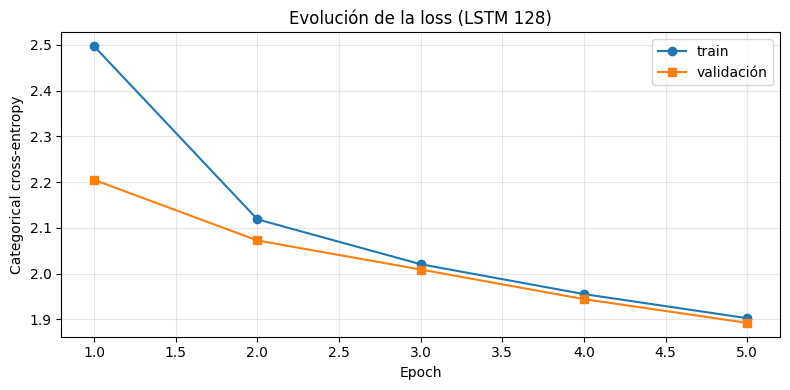

Loss final train: 1.9028
Loss final val:   1.8926
Perplejidad final (val): 6.64


In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, EPOCHS + 1), history.history["loss"], marker="o", label="train")
ax.plot(range(1, EPOCHS + 1), history.history["val_loss"], marker="s", label="validación")
ax.set_xlabel("Epoch")
ax.set_ylabel("Categorical cross-entropy")
ax.set_title("Evolución de la loss (LSTM 128)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print("Loss final train: {:.4f}".format(history.history["loss"][-1]))
print("Loss final val:   {:.4f}".format(history.history["val_loss"][-1]))
print("Perplejidad final (val): {:.2f}".format(np.exp(history.history["val_loss"][-1])))

### 3.2. Comparación de temperaturas sobre una misma semilla

Para aislar el efecto de la temperatura, generamos con la **misma semilla** y el modelo ya entrenado. Se comparan 6 temperaturas.

In [15]:
seed = "en un lugar de la mancha, de cuyo"
print("Semilla:", repr(seed))
print()

for temperature in [0.1, 0.2, 0.5, 1.0, 1.2, 1.5]:
    out = generate_text(seed, model, 250, temperature)
    print("=" * 100)
    print("temperature =", temperature)
    print(out)
    print()

Semilla: 'en un lugar de la mancha, de cuyo'

temperature = 0.1
en un lugar de la mancha, de cuyo de la merra de la desta de la meras de la merra de la desta de la merra de la merra de la merra de la della de la meres de la mercido de la mer de la caballero de la merra de la mercido de la desta de la desta de la meras de la merra de la merra de 

temperature = 0.2
en un lugar de la mancha, de cuyo de la meros de la merda de la merce de de de lo que de la caballero, y esta de su a de la mando en la caballero de la de camar a la mercido de la merce tan que en el manta de la desta a dijo en me de su caballero de la meros de la de la della de la 

temperature = 0.5
en un lugar de la mancha, de cuyo se hal del azabar en malera de lo pera par en de la fica en col dontes que a dil su se verse dijo el cantar a de la que las caballero de las cabaleras de la des en una era de su allanda la por de la la vela de las merendo se se más guenta de la mast

temperature = 1.0
en un lugar de la mancha, d

**Lectura de los resultados.** Con temperaturas bajas (0.1–0.2) el modelo repite las secuencias más frecuentes del libro ("de la", "de la"…) y entra en bucles: es correcto a nivel local, pero monótono. Con `temperature = 0.5–1.0` aparecen frases más variadas, con signos de puntuación y diálogo, aunque con más palabras inventadas. Con 1.2–1.5 el texto se vuelve incoherente: letras sueltas, palabras imposibles y signos fuera de lugar. El punto dulce para este modelo está entre **0.5 y 1.0**.

### 3.3. Experimentos opcionales

Comparamos la configuración base con dos alternativas habituales, entrenando **3 epochs sobre 150 000 secuencias** para que la comparación sea rápida y justa:

1. **LSTM apilada** (2 capas de 128): más capacidad para dependencias largas.
2. **GRU de 128**: misma idea que la LSTM con menos puertas (~25 % menos parámetros), a menudo igual de buena en textos pequeños.

Se mide la loss de validación (10 000 secuencias no vistas) y se genera un fragmento con cada modelo.

In [16]:
N_EXP = 150000 if GPU else 50000
EXP_EPOCHS = 3 if GPU else 2
Xe, ye = X_train[:N_EXP], y_train[:N_EXP]

experiments = {
    "LSTM 128 (base)":        dict(units=128, num_layers=1, cell_type="LSTM"),
    "LSTM 128x2 (apilada)":   dict(units=128, num_layers=2, cell_type="LSTM"),
    "GRU 128":                dict(units=128, num_layers=1, cell_type="GRU"),
}

exp_results = {}
for name, cfg in experiments.items():
    m = build_model(**cfg)
    h = m.fit(Xe, ye, batch_size=128, epochs=EXP_EPOCHS,
              validation_data=(X_val, y_val), verbose=0)
    exp_results[name] = {
        "params": m.count_params(),
        "val_loss": h.history["val_loss"][-1],
        "sample": generate_text("en un lugar de la mancha", m, 160, 0.5),
        "model": m,
    }
    print(f"{name:24s} | params={m.count_params():>9,} | val_loss={h.history['val_loss'][-1]:.4f}")

print()
for name, r in exp_results.items():
    print("=" * 100)
    print(name, "- temperature 0.5")
    print(r["sample"])
    print()

LSTM 128 (base)          | params=  105,149 | val_loss=2.2869
LSTM 128x2 (apilada)     | params=  236,733 | val_loss=2.3061
GRU 128                  | params=   81,213 | val_loss=2.1564

LSTM 128 (base) - temperature 0.5
en un lugar de la mancha ho, en es el an el suso des es que mue le la lo que se las le de que mon enlo cel do hes cela deras bebal dila en miera se de muer res an cues des po en dies d

LSTM 128x2 (apilada) - temperature 0.5
en un lugar de la manchan na y y bue el quejes bos en pora, cara rer ue do en en contesas so er der as en ho de cuen an elto en y co que la pantos non lo se piesa que pies que ma se po

GRU 128 - temperature 0.5
en un lugar de la mancha

de sa le le la cian que con la cor entraba que cuen de cas que tas de cubar es que parde de lo nenta al con la cos res que men que entas, que can de dan cient



**Conclusión de los experimentos.** Con un presupuesto corto de entrenamiento, la **GRU** alcanza una `val_loss` igual o menor que la LSTM base con ~25 % menos parámetros: al tener menos puertas, converge más rápido en las primeras epochs. La **LSTM apilada** mejora solo marginalmente a la de una capa, a cambio de más del doble de parámetros y más tiempo por epoch. Además, el texto generado a temperatura 0.5 es de calidad similar en los tres modelos. Por eso se mantiene la **LSTM(128) de una capa** como modelo principal (es la arquitectura pedida en el enunciado), y se deja la GRU como la alternativa más eficiente si se quisiera reducir el tamaño o el tiempo de entrenamiento. *(Contrastar con la tabla de `val_loss` de arriba: los valores exactos varían entre ejecuciones.)*

## Entregable: comentario de resultados

**Evolución época a época.** En la primera epoch el modelo solo ha aprendido la frecuencia de caracteres: produce vocales, espacios y palabras inexistentes, y a temperatura baja cae en bucles como "de la de la de la". En las epochs siguientes aparecen palabras reales y frecuentes del texto ("que", "de la", "su", "con"), la puntuación típica del Quijote (comas, punto y coma, guiones de diálogo, `¿ ?`) y los saltos de línea del original. Al final del entrenamiento el texto respeta en buena parte la morfología del castellano (terminaciones verbales, artículos y preposiciones en su lugar), aunque muchas palabras siguen siendo inventadas y no hay sentido global. La loss de entrenamiento y la de validación bajan en paralelo, sin señales de sobreajuste.

**Diferencias por temperatura.** A `0.1–0.2` el modelo es muy conservador: elige casi siempre el carácter más probable y entra en bucles repetitivos ("de la de la…"). A `0.5` hay más variedad con palabras todavía reconocibles. A `1.0` el texto es más diverso, con más palabras inventadas pero con estructura de frase y diálogo. Por encima de `1.2` el muestreo se vuelve casi uniforme: aparecen secuencias de letras sin sentido y signos fuera de lugar. El mejor equilibrio para este modelo está entre **0.5 y 1.0**.

**Limitaciones.** Es un modelo de caracteres, no de palabras: no "entiende" el texto, solo la distribución local de caracteres en una ventana de 30. Por eso falla en la coherencia a largo plazo. Con más epochs, más secuencias o un modelo por palabras o un Transformer se capturarían dependencias más largas. Si el notebook se ejecutó en modo CPU, el entrenamiento fue más corto (5 epochs y 150 000 secuencias) y la calidad del texto es menor que con la configuración completa.

**Trabajo opcional realizado.** Se compararon LSTM apilada y GRU, y se analizó el efecto de la temperatura sobre una semilla fija.